In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

In [2]:
df=pd.read_csv("Indian_Railway_Ticket_Confirmation_Dataset.csv")

In [3]:
df.head(10)

,Record_ID,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Journey_Date,Booking_Date,Days_Until_Journey,Travel_Class,...,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Final_Ticket_Status,Ticket_Confirmed
0,SIM000001,12075,CLT,Kozhikode,SBC,KSR Bengaluru,2023-07-19,2023-05-29,51,SL,...,0,0,28,41,66.6,4.5,0,0,CONFIRMED,1
1,SIM000002,12801,MAQ,Mangaluru Central,ERS,Ernakulam Jn,2025-11-04,2025-08-16,80,3A,...,149,116,33,0,99.3,41.0,0,1,WAITLISTED,0
2,SIM000003,12678,TVC,Thiruvananthapuram Central,ERS,Ernakulam Jn,2023-02-05,2022-11-01,96,SL,...,12,12,0,27,70.6,10.4,1,0,RAC,0
3,SIM000004,12617,CAN,Kannur,MAQ,Mangaluru Central,2025-02-17,2025-01-22,26,SL,...,74,74,0,0,95.4,44.9,0,0,RAC,0
4,SIM000005,16525,ERS,Ernakulam Jn,SBC,KSR Bengaluru,2023-11-07,2023-10-20,18,SL,...,148,138,10,27,81.1,11.7,0,1,WAITLISTED,0
5,SIM000006,22640,ERS,Ernakulam Jn,SBC,KSR Bengaluru,2025-02-12,2024-12-20,54,2A,...,70,43,27,23,78.2,14.1,0,0,CONFIRMED,1
6,SIM000007,12618,LKO,Lucknow,NDLS,New Delhi,2023-03-03,2023-02-18,13,2A,...,47,10,37,34,73.4,37.4,0,0,CONFIRMED,1
7,SIM000008,16525,MAQ,Mangaluru Central,ERS,Ernakulam Jn,2026-06-10,2026-02-26,104,SL,...,125,102,23,0,98.4,23.7,0,0,WAITLISTED,0
8,SIM000009,16526,CLT,Kozhikode,SBC,KSR Bengaluru,2024-07-28,2024-06-08,50,3A,...,25,25,0,29,62.5,4.9,1,0,CONFIRMED,1
9,SIM000010,12951,ADI,Ahmedabad,MMCT,Mumbai Central,2023-09-28,2023-08-29,30,3A,...,9,0,34,48,58.9,18.9,0,0,CONFIRMED,1


In [4]:
df.tail()

,Record_ID,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Journey_Date,Booking_Date,Days_Until_Journey,Travel_Class,...,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Final_Ticket_Status,Ticket_Confirmed
19995,SIM019996,22639,HYB,Hyderabad,SBC,KSR Bengaluru,2025-04-30,2025-03-03,58,SL,...,106,54,52,31,65.4,17.2,0,0,CONFIRMED,1
19996,SIM019997,12952,PUNE,Pune,BCT,Mumbai Central,2026-09-23,2026-06-05,110,2A,...,58,40,18,0,95.4,22.7,0,0,CONFIRMED,1
19997,SIM019998,16525,CAN,Kannur,MAQ,Mangaluru Central,2024-08-19,2024-07-03,47,1A,...,86,75,11,17,73.9,3.8,0,0,WAITLISTED,0
19998,SIM019999,12802,ADI,Ahmedabad,MMCT,Mumbai Central,2023-09-19,2023-06-01,110,2S,...,145,105,40,0,100.0,36.5,0,0,CONFIRMED,1
19999,SIM020000,12677,ERS,Ernakulam Jn,SBC,KSR Bengaluru,2024-05-07,2024-03-11,57,SL,...,50,20,30,25,54.5,33.6,0,0,CONFIRMED,1


In [5]:
df.loc[df["Final_Ticket_Status"] == "RAC", "Ticket_Confirmed"] = 1

In [6]:
df.head()

,Record_ID,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Journey_Date,Booking_Date,Days_Until_Journey,Travel_Class,...,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Final_Ticket_Status,Ticket_Confirmed
0,SIM000001,12075,CLT,Kozhikode,SBC,KSR Bengaluru,2023-07-19,2023-05-29,51,SL,...,0,0,28,41,66.6,4.5,0,0,CONFIRMED,1
1,SIM000002,12801,MAQ,Mangaluru Central,ERS,Ernakulam Jn,2025-11-04,2025-08-16,80,3A,...,149,116,33,0,99.3,41.0,0,1,WAITLISTED,0
2,SIM000003,12678,TVC,Thiruvananthapuram Central,ERS,Ernakulam Jn,2023-02-05,2022-11-01,96,SL,...,12,12,0,27,70.6,10.4,1,0,RAC,1
3,SIM000004,12617,CAN,Kannur,MAQ,Mangaluru Central,2025-02-17,2025-01-22,26,SL,...,74,74,0,0,95.4,44.9,0,0,RAC,1
4,SIM000005,16525,ERS,Ernakulam Jn,SBC,KSR Bengaluru,2023-11-07,2023-10-20,18,SL,...,148,138,10,27,81.1,11.7,0,1,WAITLISTED,0


In [7]:
df.isnull().sum()

Record_ID                    0
Train_Number                 0
Source_Station_Code          0
Source_Station_Name          0
Destination_Station_Code     0
Destination_Station_Name     0
Journey_Date                 0
Booking_Date                 0
Days_Until_Journey           0
Travel_Class                 0
Quota                        0
Booking_Channel              0
Route_Distance_KM            0
Initial_Waitlist             0
Current_Waitlist             0
Waitlist_Movement            0
Available_Seats_Indicator    0
Occupancy_Percentage         0
Cancellation_Percentage      0
Is_Weekend                   0
Holiday_Season_Indicator     0
Final_Ticket_Status          0
Ticket_Confirmed             0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Record_ID                  20000 non-null  object 
 1   Train_Number               20000 non-null  int64  
 2   Source_Station_Code        20000 non-null  object 
 3   Source_Station_Name        20000 non-null  object 
 4   Destination_Station_Code   20000 non-null  object 
 5   Destination_Station_Name   20000 non-null  object 
 6   Journey_Date               20000 non-null  object 
 7   Booking_Date               20000 non-null  object 
 8   Days_Until_Journey         20000 non-null  int64  
 9   Travel_Class               20000 non-null  object 
 10  Quota                      20000 non-null  object 
 11  Booking_Channel            20000 non-null  object 
 12  Route_Distance_KM          20000 non-null  int64  
 13  Initial_Waitlist           20000 non-null  int

In [10]:
df.describe()

,Train_Number,Days_Until_Journey,Route_Distance_KM,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Ticket_Confirmed
count,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,14780.774000,59.763950,541.50300,75.340550,52.975600,25.717000,20.697200,78.453980,20.028050,0.291100,0.133650,0.655100
std,3196.867453,34.804689,343.13277,43.574923,42.188623,17.849091,18.972135,19.130323,12.025823,0.454281,0.340284,0.475348
min,12075.000000,0.000000,140.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000
25%,12618.000000,30.000000,260.00000,38.000000,12.000000,11.000000,2.000000,65.700000,10.700000,0.000000,0.000000,0.000000
50%,12951.000000,60.000000,500.00000,76.000000,50.000000,25.000000,18.000000,82.100000,18.100000,0.000000,0.000000,1.000000
75%,16526.000000,90.000000,610.00000,113.000000,88.000000,38.000000,34.000000,95.400000,27.200000,1.000000,0.000000,1.000000
max,22640.000000,120.000000,1450.00000,150.000000,150.000000,100.000000,100.000000,100.000000,70.000000,1.000000,1.000000,1.000000


In [11]:
df.drop('Record_ID',axis=1,inplace=True)

In [12]:
print(df.columns)

Index(['Train_Number', 'Source_Station_Code', 'Source_Station_Name',
       'Destination_Station_Code', 'Destination_Station_Name', 'Journey_Date',
       'Booking_Date', 'Days_Until_Journey', 'Travel_Class', 'Quota',
       'Booking_Channel', 'Route_Distance_KM', 'Initial_Waitlist',
       'Current_Waitlist', 'Waitlist_Movement', 'Available_Seats_Indicator',
       'Occupancy_Percentage', 'Cancellation_Percentage', 'Is_Weekend',
       'Holiday_Season_Indicator', 'Final_Ticket_Status', 'Ticket_Confirmed'],
      dtype='object')


In [13]:
pd.set_option("display.max_columns", None)
df.head()

,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Journey_Date,Booking_Date,Days_Until_Journey,Travel_Class,Quota,Booking_Channel,Route_Distance_KM,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Final_Ticket_Status,Ticket_Confirmed
0,12075,CLT,Kozhikode,SBC,KSR Bengaluru,2023-07-19,2023-05-29,51,SL,GN,MakeMyTrip,500,0,0,28,41,66.6,4.5,0,0,CONFIRMED,1
1,12801,MAQ,Mangaluru Central,ERS,Ernakulam Jn,2025-11-04,2025-08-16,80,3A,GN,ConfirmTkt,430,149,116,33,0,99.3,41.0,0,1,WAITLISTED,0
2,12678,TVC,Thiruvananthapuram Central,ERS,Ernakulam Jn,2023-02-05,2022-11-01,96,SL,GN,Other,220,12,12,0,27,70.6,10.4,1,0,RAC,1
3,12617,CAN,Kannur,MAQ,Mangaluru Central,2025-02-17,2025-01-22,26,SL,GN,Other,140,74,74,0,0,95.4,44.9,0,0,RAC,1
4,16525,ERS,Ernakulam Jn,SBC,KSR Bengaluru,2023-11-07,2023-10-20,18,SL,GN,MakeMyTrip,550,148,138,10,27,81.1,11.7,0,1,WAITLISTED,0


In [14]:
df.drop('Journey_Date',axis=1,inplace=True)
df.drop('Booking_Date',axis=1,inplace=True)

In [15]:
df.head()

,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Days_Until_Journey,Travel_Class,Quota,Booking_Channel,Route_Distance_KM,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Final_Ticket_Status,Ticket_Confirmed
0,12075,CLT,Kozhikode,SBC,KSR Bengaluru,51,SL,GN,MakeMyTrip,500,0,0,28,41,66.6,4.5,0,0,CONFIRMED,1
1,12801,MAQ,Mangaluru Central,ERS,Ernakulam Jn,80,3A,GN,ConfirmTkt,430,149,116,33,0,99.3,41.0,0,1,WAITLISTED,0
2,12678,TVC,Thiruvananthapuram Central,ERS,Ernakulam Jn,96,SL,GN,Other,220,12,12,0,27,70.6,10.4,1,0,RAC,1
3,12617,CAN,Kannur,MAQ,Mangaluru Central,26,SL,GN,Other,140,74,74,0,0,95.4,44.9,0,0,RAC,1
4,16525,ERS,Ernakulam Jn,SBC,KSR Bengaluru,18,SL,GN,MakeMyTrip,550,148,138,10,27,81.1,11.7,0,1,WAITLISTED,0


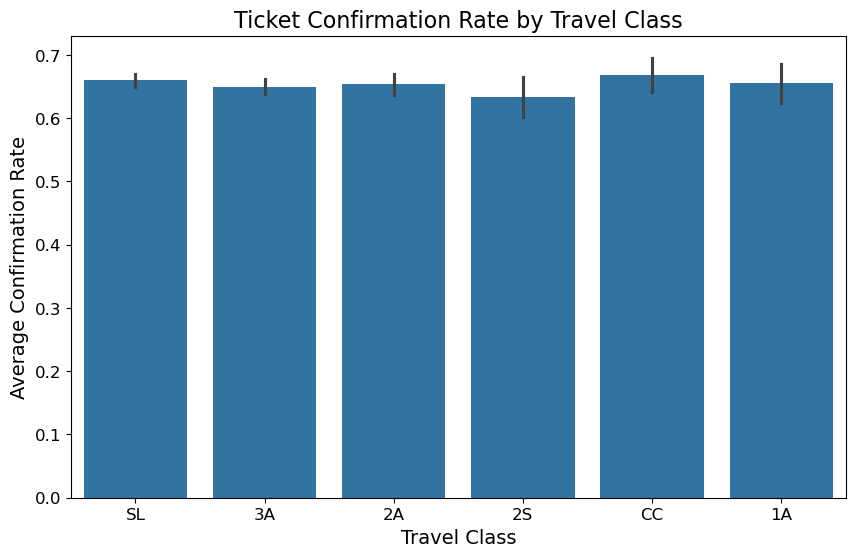

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(x='Travel_Class',y='Ticket_Confirmed',data=df)

plt.title('Ticket Confirmation Rate by Travel Class', fontsize=16)
plt.xlabel('Travel Class', fontsize=14)
plt.ylabel('Average Confirmation Rate', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

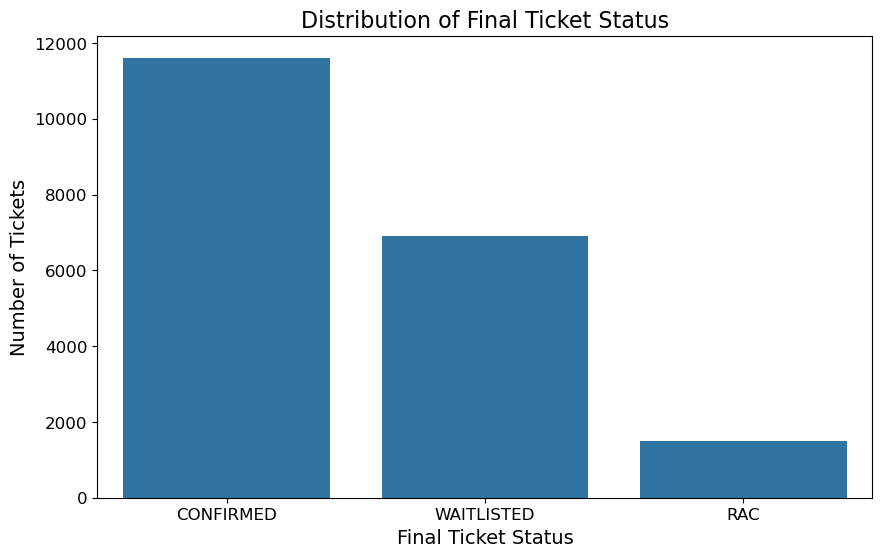

In [17]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x='Final_Ticket_Status',
    data=df
)

plt.title('Distribution of Final Ticket Status', fontsize=16)
plt.xlabel('Final Ticket Status', fontsize=14)
plt.ylabel('Number of Tickets', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.show()

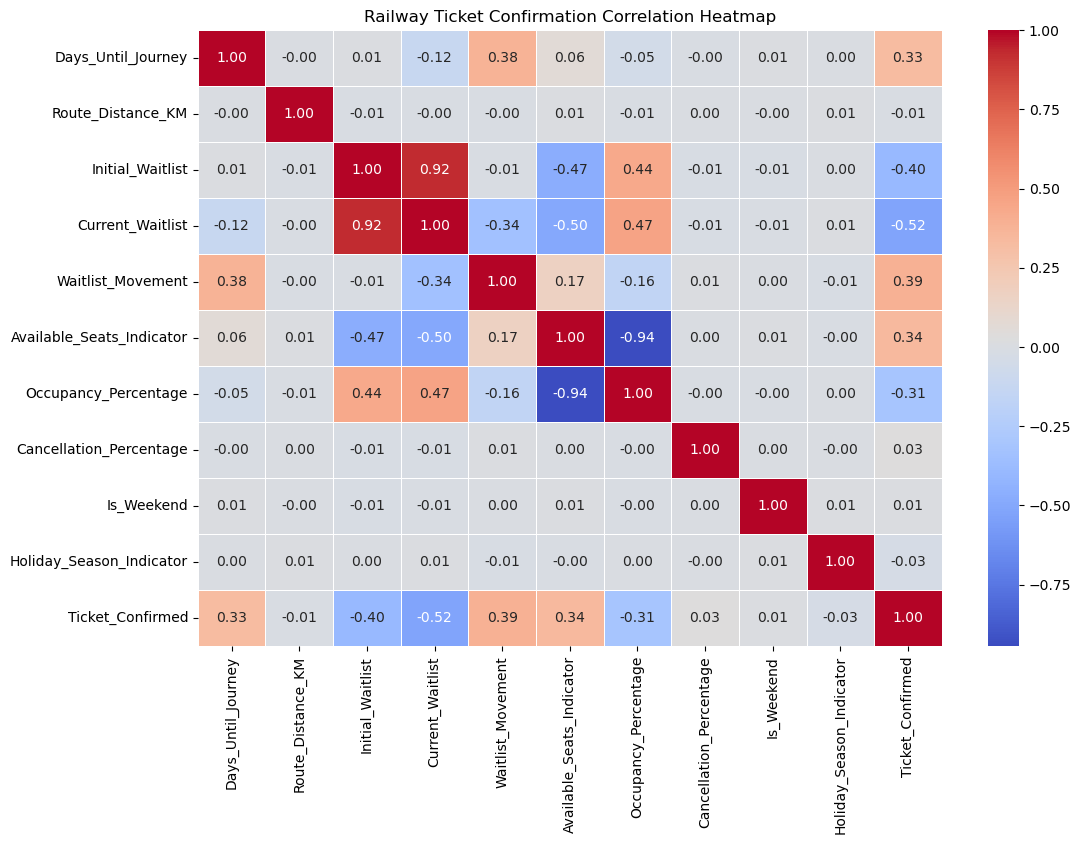

In [18]:
plt.figure(figsize=(12, 8)) 
corr = df[[ "Days_Until_Journey", "Route_Distance_KM", "Initial_Waitlist", "Current_Waitlist", "Waitlist_Movement", "Available_Seats_Indicator", "Occupancy_Percentage", "Cancellation_Percentage", "Is_Weekend", "Holiday_Season_Indicator", "Ticket_Confirmed" ]].corr(numeric_only=True) 
sns.heatmap( corr, annot=True, linewidths=0.5, cmap="coolwarm", fmt=".2f" ) 
plt.title("Railway Ticket Confirmation Correlation Heatmap") 
plt.show()

In [19]:
le1=LabelEncoder()
le2=LabelEncoder()
le3=LabelEncoder()
le4=LabelEncoder()
le5=LabelEncoder()
le6=LabelEncoder()
le7=LabelEncoder()
df['Source_Station_Code']=le1.fit_transform(df['Source_Station_Code'])
df['Source_Station_Name']=le2.fit_transform(df['Source_Station_Name'])
df['Destination_Station_Code']=le3.fit_transform(df['Destination_Station_Code'])
df['Destination_Station_Name']=le4.fit_transform(df['Destination_Station_Name'])
df['Travel_Class']=le5.fit_transform(df['Travel_Class'])
df['Quota']=le6.fit_transform(df['Quota'])
df['Booking_Channel']=le7.fit_transform(df['Booking_Channel'])

In [20]:
df.drop('Final_Ticket_Status',axis=1,inplace=True)

In [21]:
df.head(20)

,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Days_Until_Journey,Travel_Class,Quota,Booking_Channel,Route_Distance_KM,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator,Ticket_Confirmed
0,12075,4,9,6,2,51,5,0,2,500,0,0,28,41,66.6,4.5,0,0,1
1,12801,10,12,1,1,80,3,0,0,430,149,116,33,0,99.3,41.0,0,1,0
2,12678,16,15,1,1,96,5,0,3,220,12,12,0,27,70.6,10.4,1,0,1
3,12617,2,8,2,3,26,5,0,3,140,74,74,0,0,95.4,44.9,0,0,1
4,16525,5,4,6,2,18,5,0,2,550,148,138,10,27,81.1,11.7,0,1,0
5,22640,5,4,6,2,54,1,0,1,550,70,43,27,23,78.2,14.1,0,0,1
6,12618,9,10,5,5,13,1,0,3,490,47,10,37,34,73.4,37.4,0,0,1
7,16525,10,12,1,1,104,5,2,1,430,125,102,23,0,98.4,23.7,0,0,0
8,16526,4,9,6,2,50,3,0,0,500,25,25,0,29,62.5,4.9,1,0,1
9,12951,0,0,4,4,30,3,4,1,490,9,0,34,48,58.9,18.9,0,0,1


In [22]:
x=df.drop("Ticket_Confirmed",axis=1)
y=df['Ticket_Confirmed']

In [23]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)
x_test

,Train_Number,Source_Station_Code,Source_Station_Name,Destination_Station_Code,Destination_Station_Name,Days_Until_Journey,Travel_Class,Quota,Booking_Channel,Route_Distance_KM,Initial_Waitlist,Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,Holiday_Season_Indicator
10650,16604,16,15,1,1,65,1,2,3,220,49,23,26,0,100.0,32.1,1,0
2041,12802,14,14,0,4,105,3,0,2,190,150,119,31,24,78.8,25.4,0,0
8668,12201,1,1,5,5,35,5,0,0,780,85,65,20,0,94.3,6.4,0,0
1114,12202,5,4,6,2,47,3,0,0,550,59,49,10,0,92.1,11.7,1,0
13902,12201,10,12,1,1,27,1,0,1,430,70,47,23,19,86.8,12.2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4464,12677,4,9,1,1,14,3,2,0,190,59,52,7,1,100.0,2.9,1,0
15656,12075,8,7,5,5,25,4,1,2,300,131,130,1,0,86.3,20.2,0,0
19146,16525,7,6,6,2,19,2,0,1,570,86,86,0,0,93.1,11.0,0,0
10567,12802,9,10,5,5,88,3,0,2,490,133,100,33,21,82.9,29.5,1,0


## RANDOM FORREST REGRESSOR

In [25]:
rf = RandomForestClassifier(n_estimators=120, random_state=42)

In [28]:
rf.fit(x_train, y_train)

RandomForestClassifier(n_estimators=120, random_state=42)

In [34]:
rf_y_pred=rf.predict(x_test)

In [43]:
print("Accuracy:", accuracy_score(y_test, rf_y_pred)) 
print("Precision:", precision_score(y_test, rf_y_pred)) 
print("Recall:", recall_score(y_test, rf_y_pred))
print("F1 Score:", f1_score(y_test, rf_y_pred)) 
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_y_pred)) 
print("classification_report:\n",classification_report(y_test, rf_y_pred))

Accuracy: 0.8116666666666666
Precision: 0.855196770938446
Recall: 0.8590978205778003
F1 Score: 0.8571428571428571
Confusion Matrix:
 [[1480  574]
 [ 556 3390]]
classification_report:
               precision    recall  f1-score   support

           0       0.73      0.72      0.72      2054
           1       0.86      0.86      0.86      3946

    accuracy                           0.81      6000
   macro avg       0.79      0.79      0.79      6000
weighted avg       0.81      0.81      0.81      6000



## Logistics Regression

In [46]:
model=LogisticRegression()
model.fit(x_train,y_train)

LogisticRegression()

In [48]:
y_pred=model.predict(x_test)
y_pred

array([1, 1, 0, ..., 0, 1, 1], dtype=int64)

In [49]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred)) 
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred)) 
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred)) 
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8076666666666666
Precision: 0.8338115734098518
Recall: 0.8836796756208819
F1 Score: 0.8580216535433071
Confusion Matrix:
 [[1359  695]
 [ 459 3487]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.66      0.70      2054
           1       0.83      0.88      0.86      3946

    accuracy                           0.81      6000
   macro avg       0.79      0.77      0.78      6000
weighted avg       0.80      0.81      0.80      6000



## Decision Tree

In [58]:
model2 = DecisionTreeClassifier()
model2.fit(x_train, y_train)

DecisionTreeClassifier()

In [60]:
ypred = model2.predict(x_test)

In [66]:
print("Accuracy:", accuracy_score(y_test, ypred))
print("Precision:", precision_score(y_test, ypred)) 
print("Recall:", recall_score(y_test, ypred))
print("F1 Score:", f1_score(y_test, ypred)) 
print("Confusion Matrix:\n", confusion_matrix(y_test, ypred)) 
print("Classification Report:\n", classification_report(y_test, ypred))

Accuracy: 0.7328333333333333
Precision: 0.7938299473288186
Recall: 0.8020780537252914
F1 Score: 0.7979326862473213
Confusion Matrix:
 [[1232  822]
 [ 781 3165]]
Classification Report:
               precision    recall  f1-score   support

           0       0.61      0.60      0.61      2054
           1       0.79      0.80      0.80      3946

    accuracy                           0.73      6000
   macro avg       0.70      0.70      0.70      6000
weighted avg       0.73      0.73      0.73      6000



## simple prediction

In [71]:
input_data = (12678,16,15,1,1,96,5,0,3,220,12,12,0,27,70.6,10.4,1,0)

# Convert input data to a numpy array
input_data_as_numpy_array = np.array(input_data)

# Reshape the data as we're predicting for one instance
input_data_reshape = input_data_as_numpy_array.reshape(1, -1)
print(input_data_reshape)

# Make prediction using your trained model
prediction = rf.predict(input_data_reshape)

print("Predicted Confirmed Ticket: ", prediction[0])

[[1.2678e+04 1.6000e+01 1.5000e+01 1.0000e+00 1.0000e+00 9.6000e+01
  5.0000e+00 0.0000e+00 3.0000e+00 2.2000e+02 1.2000e+01 1.2000e+01
  0.0000e+00 2.7000e+01 7.0600e+01 1.0400e+01 1.0000e+00 0.0000e+00]]
Predicted Confirmed Ticket:  1


In [73]:
input_data = df.iloc[2][x_train.columns].values

input_data_reshape = input_data.reshape(1, -1)

prediction = rf.predict(input_data_reshape)

print("Actual:", df.iloc[2]['Ticket_Confirmed'])
print("Predicted:", prediction[0])

Actual: 1.0
Predicted: 1


In [75]:
import pickle

In [77]:
filename='trained_project_model.sav'
pickle.dump(rf,open(filename,'wb'))
loaded_model=pickle.load(open(filename,'rb'))
loaded_model

RandomForestClassifier(n_estimators=120, random_state=42)

In [79]:
import gradio as gr

In [80]:
# save encoders to files
with open('obj1.pkl','wb') as f:
    pickle.dump(le1,f)
with open('obj2.pkl','wb') as f:
    pickle.dump(le2,f)
with open('obj3.pkl','wb') as f:
    pickle.dump(le3,f)
with open('obj4.pkl','wb') as f:
    pickle.dump(le4,f)
with open('obj5.pkl','wb') as f:
    pickle.dump(le5,f)
with open('obj6.pkl','wb') as f:
    pickle.dump(le6,f)
with open('obj7.pkl','wb') as f:
    pickle.dump(le7,f)

In [81]:
"""
# Load model
model = pickle.load(open("trained_project_model.sav", "rb"))

# Load Label encoders
obj1 = pickle.load(open("obj1.pkl", "rb"))
obj2 = pickle.load(open("obj2.pkl", "rb"))
obj3 = pickle.load(open("obj3.pkl", "rb"))
obj4 = pickle.load(open("obj4.pkl", "rb"))
obj5 = pickle.load(open("obj5.pkl", "rb"))
obj6 = pickle.load(open("obj6.pkl", "rb"))
obj7 = pickle.load(open("obj7.pkl", "rb"))

# Get Label options for dropdowns
Source_Station_Code_option = obj1.classes_.tolist()
Source_Station_Name_option = obj2.classes_.tolist()
Destination_Station_Code_option= obj3.classes_.tolist()
Destination_Station_Name_option= obj4.classes_.tolist()
Travel_Class_option= obj5.classes_.tolist()
Quota_option= obj6.classes_.tolist()
Booking_Channel_option= obj7.classes_.tolist()

# Define prediction function
def predict_ConfirmedTicket(Train_Number,Source_Station_Code_str,Source_Station_Name_str,
       Destination_Station_Code_str,Destination_Station_Name_str,Days_Until_Journey,Travel_Class_str,Quota_str,
       Booking_Channel_str,Route_Distance_KM,Initial_Waitlist,
       Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,
       Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,
       Holiday_Season_Indicator):
    try:
        # Corrected to use obj1 and obj2
        Source_Station_Code = obj1.transform([Source_Station_Code_str])[0]
        Source_Station_Name = obj2.transform([Source_Station_Name_str])[0]
        Destination_Station_Code = obj3.transform([Destination_Station_Code_str])[0]
        Destination_Station_Name= obj4.transform([Destination_Station_Name_str])[0]
        Travel_Class= obj5.transform([Travel_Class_str])[0]
        Quota = obj6.transform([Quota_str])[0]
        Booking_Channel = obj7.transform([Booking_Channel_str])[0]

    except ValueError:
        return "Invalid description.Please select from the dropdown."
        
    input_data = np.array([Train_Number,Source_Station_Code,Source_Station_Name,
       Destination_Station_Code,Destination_Station_Name,Days_Until_Journey,Travel_Class,Quota,
       Booking_Channel,Route_Distance_KM,Initial_Waitlist,
       Current_Waitlist,Waitlist_Movement,Available_Seats_Indicator,
       Occupancy_Percentage,Cancellation_Percentage,Is_Weekend,
       Holiday_Season_Indicator]).reshape(1, -1)
    
    prediction = model.predict(input_data)
    if prediction[0] == 1:
        return "Prediction: Ticket Confirmed"
    else:
        return "Prediction: Ticket Not Confirmed"

# Create Gradio interface
iface = gr.Interface(
    fn=predict_ConfirmedTicket,
    inputs=[
        gr.Number(label="Train Number"),
        gr.Dropdown(choices=Source_Station_Code_option, label="Source Station Code"),
        gr.Dropdown(choices=Source_Station_Name_option, label="source station Name"),
        gr.Dropdown(choices=Destination_Station_Code_option, label="Destination station code"),
        gr.Dropdown(choices=Destination_Station_Name_option, label="Destination station Name"),
        gr.Number(label="Days Until Journey"),
        gr.Dropdown(choices=Travel_Class_option, label="Travel Class"),
        gr.Dropdown(choices=Quota_option, label="Quota"),
        gr.Dropdown(choices=Booking_Channel_option, label="Booking Channel"),
        gr.Number(label="Route Distance KM"),
        gr.Number(label="Initial Waitlist"),
        gr.Number(label="Current Waitlist"),
        gr.Number(label="Waitlist Movement"),
        gr.Number(label="Available Seats Indicator"),
        gr.Number(label="Occupancy Percentage"),
        gr.Number(label="Cancellation Percentage"),
        gr.Slider(0, 1, step=1, label="Is Weekend"),
        gr.Slider(0, 1, step=1, label="Holiday Season Indicator"),
    ],
    outputs="text",
    title="🚆Indian Railway Ticket Confirmation Prediction",
    description="Enter ticket details to predict ticket confirmation using a trained ML model."
)

#launch the interface
iface.launch()
"""

'\n# Load model\nmodel = pickle.load(open("trained_project_model.sav", "rb"))\n\n# Load Label encoders\nobj1 = pickle.load(open("obj1.pkl", "rb"))\nobj2 = pickle.load(open("obj2.pkl", "rb"))\nobj3 = pickle.load(open("obj3.pkl", "rb"))\nobj4 = pickle.load(open("obj4.pkl", "rb"))\nobj5 = pickle.load(open("obj5.pkl", "rb"))\nobj6 = pickle.load(open("obj6.pkl", "rb"))\nobj7 = pickle.load(open("obj7.pkl", "rb"))\n\n# Get Label options for dropdowns\nSource_Station_Code_option = obj1.classes_.tolist()\nSource_Station_Name_option = obj2.classes_.tolist()\nDestination_Station_Code_option= obj3.classes_.tolist()\nDestination_Station_Name_option= obj4.classes_.tolist()\nTravel_Class_option= obj5.classes_.tolist()\nQuota_option= obj6.classes_.tolist()\nBooking_Channel_option= obj7.classes_.tolist()\n\n# Define prediction function\ndef predict_ConfirmedTicket(Train_Number,Source_Station_Code_str,Source_Station_Name_str,\n       Destination_Station_Code_str,Destination_Station_Name_str,Days_Until_J

In [85]:
print("Model features:", model.n_features_in_)
print("Model type:", type(model))

Model features: 18
Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>


In [88]:

# ------------------------------------------------------------------
# Load model & label encoders
# ------------------------------------------------------------------
def load_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)
 
 
model = load_pickle("trained_project_model.sav")
obj1, obj2, obj3, obj4, obj5, obj6, obj7 = (load_pickle(f"obj{i}.pkl") for i in range(1, 8))
 
Source_Station_Code_option = obj1.classes_.tolist()
Source_Station_Name_option = obj2.classes_.tolist()
Destination_Station_Code_option = obj3.classes_.tolist()
Destination_Station_Name_option = obj4.classes_.tolist()
Travel_Class_option = obj5.classes_.tolist()
Quota_option = obj6.classes_.tolist()
Booking_Channel_option = obj7.classes_.tolist()
 
 
# ------------------------------------------------------------------
# Result rendering
# ------------------------------------------------------------------
ICONS = {
    "success": '<svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.4" '
               'stroke-linecap="round" stroke-linejoin="round"><path d="M5 12.5l4.5 4.5L19 7.5"/></svg>',
    "danger":  '<svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.4" '
               'stroke-linecap="round" stroke-linejoin="round"><path d="M6 6l12 12M18 6L6 18"/></svg>',
    "warning": '<svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.2" '
               'stroke-linecap="round" stroke-linejoin="round"><path d="M12 8v5M12 16.5v.01"/>'
               '<circle cx="12" cy="12" r="9"/></svg>',
    "idle":    '<svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" '
               'stroke-linecap="round" stroke-linejoin="round"><circle cx="12" cy="12" r="9"/>'
               '<path d="M12 7v5l3 2"/></svg>',
}
 
 
def result_bar(kind, badge, title, message, probability=None):
    ring_html = ""
    if probability is not None:
        pct = probability * 100
        ring_html = f"""
        <div class="ring-wrap">
            <div class="ring {kind}" style="--p:{pct:.1f}"><span>{pct:.0f}%</span></div>
            <div class="ring-cap">Confirmation<br>probability</div>
        </div>"""
    return f"""
    <div class="result {kind}">
        <div class="r-icon {kind}">{ICONS[kind]}</div>
        <div class="r-main">
            <span class="r-badge {kind}">{badge}</span>
            <div class="r-title">{title}</div>
            <div class="r-msg">{message}</div>
        </div>
        {ring_html}
    </div>"""
 
 
EMPTY_RESULT = result_bar(
    "idle", "Ready", "Awaiting your input",
    "Complete the three sections above, then select Predict.",
)
 
 
# ------------------------------------------------------------------
# Prediction
# ------------------------------------------------------------------
def predict_ConfirmedTicket(
    Train_Number, Source_Station_Code_str, Source_Station_Name_str,
    Destination_Station_Code_str, Destination_Station_Name_str,
    Days_Until_Journey, Travel_Class_str, Quota_str, Booking_Channel_str,
    Route_Distance_KM, Initial_Waitlist, Current_Waitlist, Waitlist_Movement,
    Available_Seats_Indicator, Occupancy_Percentage, Cancellation_Percentage,
    Is_Weekend, Holiday_Season_Indicator,
):
    dropdowns = [
        Source_Station_Code_str, Source_Station_Name_str,
        Destination_Station_Code_str, Destination_Station_Name_str,
        Travel_Class_str, Quota_str, Booking_Channel_str,
    ]
    numbers = [
        Train_Number, Days_Until_Journey, Route_Distance_KM, Initial_Waitlist,
        Current_Waitlist, Waitlist_Movement, Available_Seats_Indicator,
        Occupancy_Percentage, Cancellation_Percentage,
    ]
    if any(d is None or d == "" for d in dropdowns) or any(n is None for n in numbers):
        return result_bar("warning", "Incomplete", "Missing information",
                          "Please complete all fields before predicting.")
 
    if not (0 <= Occupancy_Percentage <= 100 and 0 <= Cancellation_Percentage <= 100):
        return result_bar("warning", "Invalid", "Percentage out of range",
                          "Occupancy and cancellation must be between 0 and 100.")
 
    if Days_Until_Journey < 0 or Route_Distance_KM < 0:
        return result_bar("warning", "Invalid", "Negative value",
                          "Days until journey and route distance cannot be negative.")
 
    try:
        Source_Station_Code = obj1.transform([Source_Station_Code_str])[0]
        Source_Station_Name = obj2.transform([Source_Station_Name_str])[0]
        Destination_Station_Code = obj3.transform([Destination_Station_Code_str])[0]
        Destination_Station_Name = obj4.transform([Destination_Station_Name_str])[0]
        Travel_Class = obj5.transform([Travel_Class_str])[0]
        Quota = obj6.transform([Quota_str])[0]
        Booking_Channel = obj7.transform([Booking_Channel_str])[0]
    except ValueError:
        return result_bar("warning", "Invalid", "Invalid selection",
                          "Please choose values from the dropdown lists.")
 
    # Feature order must match the order used during training
    input_data = np.array([
        Train_Number, Source_Station_Code, Source_Station_Name,
        Destination_Station_Code, Destination_Station_Name, Days_Until_Journey,
        Travel_Class, Quota, Booking_Channel, Route_Distance_KM,
        Initial_Waitlist, Current_Waitlist, Waitlist_Movement,
        Available_Seats_Indicator, Occupancy_Percentage,
        Cancellation_Percentage, int(Is_Weekend), int(Holiday_Season_Indicator),
    ], dtype=float).reshape(1, -1)
 
    prediction = model.predict(input_data)[0]
 
    probability = None
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(input_data)[0]
        classes = list(model.classes_)
        probability = float(proba[classes.index(1)]) if 1 in classes else float(proba[-1])
 
    if prediction == 1:
        return result_bar("success", "Confirmed", "Ticket likely to be confirmed",
                          "Based on the supplied details, confirmation is expected.", probability)
    return result_bar("danger", "Not confirmed", "Ticket unlikely to be confirmed",
                      "Based on the supplied details, confirmation is not expected.", probability)
 
 
# ------------------------------------------------------------------
# Theme & CSS
# ------------------------------------------------------------------
theme = gr.themes.Base(
    primary_hue="blue",
    neutral_hue="slate",
    radius_size=gr.themes.sizes.radius_md,
    font=[gr.themes.GoogleFont("Inter"), "ui-sans-serif", "system-ui", "sans-serif"],
).set(
    body_background_fill="#eef2f7",
    body_background_fill_dark="#0a0f1d",
    block_background_fill="#ffffff",
    block_background_fill_dark="#131a2b",
    block_border_color="#e3e8ef",
    block_border_color_dark="#243049",
    block_shadow="none",
    block_title_background_fill="transparent",
    block_title_text_color="#475467",
    block_title_text_color_dark="#a8b3c7",
    block_title_text_size="13px",
    block_title_text_weight="500",
    block_title_padding="0 0 4px 0",
    block_label_background_fill="transparent",
    input_background_fill="#f9fafb",
    input_background_fill_dark="#0f1626",
    input_border_color="#d0d5dd",
    input_border_color_dark="#2b3750",
    input_shadow="none",
)
 
CSS = """
.gradio-container {max-width: 1240px !important; margin: 0 auto !important; padding: 10px 20px 6px !important;}
footer {display: none !important;}
 
/* =============== HERO =============== */
.hero {
    position: relative; display: flex; align-items: center; justify-content: space-between;
    gap: 20px; flex-wrap: wrap;
    padding: 14px 24px; margin-bottom: 12px; border-radius: 14px; color: #fff;
    background:
        radial-gradient(900px 260px at 100% 0%, rgba(56,189,248,.35), transparent 60%),
        radial-gradient(600px 240px at 0% 100%, rgba(99,102,241,.35), transparent 60%),
        linear-gradient(135deg, #0b1b44 0%, #12306f 55%, #1d4ed8 100%);
    box-shadow: 0 12px 30px rgba(15, 42, 94, .28);
}
.hero-left {display: flex; align-items: center; gap: 18px;}
.logo {
    flex: none; width: 46px; height: 46px; border-radius: 12px;
    display: flex; align-items: center; justify-content: center;
    background: rgba(255,255,255,.14); border: 1px solid rgba(255,255,255,.28);
    backdrop-filter: blur(6px);
}
.logo svg {width: 25px; height: 25px;}
.eyebrow {font-size: .7rem; font-weight: 650; letter-spacing: .14em; text-transform: uppercase; color: #93c5fd; margin-bottom: 4px;}
.hero h1 {margin: 0; font-size: 1.5rem; font-weight: 750; letter-spacing: -.025em; line-height: 1.15; color: #fff;}
.hero p  {margin: 3px 0 0; font-size: .85rem; color: #cfe0ff;}
.hero-stats {display: flex; gap: 10px; flex-wrap: wrap;}
.stat {
    min-width: 84px; text-align: center; padding: 6px 12px; border-radius: 10px;
    background: rgba(255,255,255,.10); border: 1px solid rgba(255,255,255,.20);
}
.stat b {display: block; font-size: 1rem; font-weight: 700; color: #fff;}
.stat span {font-size: .68rem; letter-spacing: .06em; text-transform: uppercase; color: #bcd3ff;}
 
/* =============== CARDS =============== */
.card {
    position: relative;
    background: var(--block-background-fill) !important;
    border: 1px solid var(--border-color-primary) !important;
    border-radius: 14px !important;
    padding: 12px 16px 12px !important;
    gap: 6px !important;
    box-shadow: 0 1px 2px rgba(16,24,40,.05), 0 8px 20px rgba(16,24,40,.06) !important;
}
.card::before {
    content: ""; position: absolute; top: -1px; left: -1px; right: -1px; height: 4px;
    border-radius: 14px 14px 0 0;
    background: linear-gradient(90deg, #1d4ed8, #38bdf8);
}
.card .block, .card .form {
    background: transparent !important; border: none !important;
    box-shadow: none !important; padding: 0 !important;
}
.card .row {gap: 10px !important;}
 
.card-head {display: flex; align-items: center; gap: 10px; padding: 2px 0 8px;
            border-bottom: 1px solid var(--border-color-primary); margin-bottom: 2px;}
.step {
    flex: none; width: 26px; height: 26px; border-radius: 50%;
    display: flex; align-items: center; justify-content: center;
    font-size: .8rem; font-weight: 700; color: #fff;
    background: linear-gradient(135deg, #1d4ed8, #0ea5e9);
    box-shadow: 0 3px 8px rgba(29,78,216,.35);
}
.card-title {font-size: .92rem; font-weight: 650; letter-spacing: .01em; color: var(--body-text-color);}
 
/* inputs */
.card input[type="number"], .card input[type="text"] {font-size: .92rem !important; border-radius: 8px !important;}
.card input:focus {
    border-color: #2563eb !important;
    box-shadow: 0 0 0 3px rgba(37,99,235,.16) !important;
}
 
/* =============== BUTTONS =============== */
#predict-btn {
    background: linear-gradient(135deg, #1d4ed8 0%, #0ea5e9 100%) !important;
    color: #fff !important; border: none !important; font-weight: 650 !important;
    font-size: 1rem !important; letter-spacing: .02em; min-height: 48px;
    border-radius: 10px !important;
    box-shadow: 0 8px 18px rgba(29,78,216,.32) !important;
    transition: transform .12s ease, box-shadow .12s ease, filter .12s ease;
}
#predict-btn:hover {transform: translateY(-1px); filter: brightness(1.06); box-shadow: 0 12px 22px rgba(29,78,216,.38) !important;}
#predict-btn:active {transform: translateY(0);}
#reset-btn {
    background: transparent !important; border: 1px solid var(--border-color-primary) !important;
    color: var(--body-text-color-subdued) !important; border-radius: 10px !important;
}
#reset-btn:hover {border-color: #2563eb !important; color: #2563eb !important;}
 
/* =============== RESULT =============== */
.result {
    display: flex; align-items: center; gap: 18px;
    padding: 10px 18px; border-radius: 14px;
    background: var(--block-background-fill);
    border: 1px solid var(--border-color-primary);
    box-shadow: 0 1px 2px rgba(16,24,40,.05), 0 8px 20px rgba(16,24,40,.06);
}
.result.success {background: linear-gradient(90deg, rgba(22,163,74,.09), transparent 55%), var(--block-background-fill);}
.result.danger  {background: linear-gradient(90deg, rgba(220,38,38,.08), transparent 55%), var(--block-background-fill);}
.result.warning {background: linear-gradient(90deg, rgba(217,119,6,.09), transparent 55%), var(--block-background-fill);}
 
.r-icon {
    flex: none; width: 44px; height: 44px; border-radius: 50%;
    display: flex; align-items: center; justify-content: center;
}
.r-icon svg {width: 26px; height: 26px;}
.r-icon.idle    {background: rgba(152,162,179,.18); color: #667085;}
.r-icon.success {background: #16a34a; color: #fff; box-shadow: 0 6px 14px rgba(22,163,74,.35);}
.r-icon.danger  {background: #dc2626; color: #fff; box-shadow: 0 6px 14px rgba(220,38,38,.35);}
.r-icon.warning {background: #d97706; color: #fff; box-shadow: 0 6px 14px rgba(217,119,6,.35);}
 
.r-main  {flex: 1; min-width: 0;}
.r-badge {
    display: inline-block; font-size: .68rem; font-weight: 700; letter-spacing: .08em;
    text-transform: uppercase; padding: 3px 10px; border-radius: 999px; margin-bottom: 5px;
}
.r-badge.idle    {background: rgba(152,162,179,.2);  color: #667085;}
.r-badge.success {background: rgba(22,163,74,.14);   color: #15803d;}
.r-badge.danger  {background: rgba(220,38,38,.12);   color: #b91c1c;}
.r-badge.warning {background: rgba(217,119,6,.14);   color: #b45309;}
.dark .r-badge.success {color: #4ade80;}
.dark .r-badge.danger  {color: #f87171;}
.dark .r-badge.warning {color: #fbbf24;}
.r-title {font-size: 1.15rem; font-weight: 700; color: var(--body-text-color); letter-spacing: -.01em;}
.r-msg   {font-size: .87rem; color: var(--body-text-color-subdued); margin-top: 2px;}
 
/* probability ring */
.ring-wrap {display: flex; align-items: center; gap: 12px;}
.ring {
    --c: #98a2b3;
    position: relative; width: 62px; height: 62px; border-radius: 50%;
    display: grid; place-items: center;
    background: conic-gradient(var(--c) calc(var(--p) * 1%), rgba(152,162,179,.25) 0);
}
.ring.success {--c: #16a34a;}
.ring.danger  {--c: #dc2626;}
.ring::before {content: ""; position: absolute; inset: 7px; border-radius: 50%; background: var(--block-background-fill);}
.ring span {position: relative; font-size: .95rem; font-weight: 750; color: var(--body-text-color);}
.ring-cap {font-size: .74rem; line-height: 1.3; letter-spacing: .04em; text-transform: uppercase; color: var(--body-text-color-subdued);}
 
.note {font-size: .78rem; color: var(--body-text-color-subdued); text-align: center; margin: 0; padding: 0;}
#note-box {padding: 0 !important; min-height: 0 !important; margin-top: -10px !important; border: none !important; background: transparent !important;}
#result-box {padding: 0 !important; border: none !important; background: transparent !important;}
 
@media (max-width: 760px) {
    .hero h1 {font-size: 1.4rem;}
    .result {flex-wrap: wrap;}
}
"""
 
 
# ------------------------------------------------------------------
# UI
# ------------------------------------------------------------------
with gr.Blocks(theme=theme, css=CSS, title="Railway Ticket Confirmation Predictor") as demo:
 
    gr.HTML("""
    <div class="hero">
        <div class="hero-left">
            <div class="logo">
                <svg viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="1.7"
                     stroke-linecap="round" stroke-linejoin="round">
                    <rect x="5" y="3" width="14" height="14" rx="3"/>
                    <path d="M5 11h14"/>
                    <circle cx="9" cy="14" r="0.7" fill="#ffffff"/>
                    <circle cx="15" cy="14" r="0.7" fill="#ffffff"/>
                    <path d="M8 21l2-4M16 21l-2-4"/>
                </svg>
            </div>
            <div>
                <div class="eyebrow">Indian Railways &middot; Waitlist Intelligence</div>
                <h1>Railway Ticket Confirmation Predictor</h1>
                <p>Estimate the likelihood that a waitlisted ticket will be confirmed.</p>
            </div>
        </div>
        <div class="hero-stats">
            <div class="stat"><b>18</b><span>Input features</span></div>
            <div class="stat"><b>ML</b><span>Powered</span></div>
            <div class="stat"><b>Instant</b><span>Result</span></div>
        </div>
    </div>
    """)
 
    with gr.Row(equal_height=True):
        # ---------------- Card 1: Journey ----------------
        with gr.Column(scale=1, min_width=300, elem_classes="card"):
            gr.HTML('<div class="card-head"><span class="step">1</span><span class="card-title">Journey</span></div>')
            with gr.Row():
                Train_Number = gr.Number(label="Train Number", precision=0)
                Route_Distance_KM = gr.Number(label="Distance (KM)", minimum=0)
            with gr.Row():
                Source_Code = gr.Dropdown(Source_Station_Code_option, label="Source Code", filterable=True)
                Source_Name = gr.Dropdown(Source_Station_Name_option, label="Source Station", filterable=True)
            with gr.Row():
                Dest_Code = gr.Dropdown(Destination_Station_Code_option, label="Destination Code", filterable=True)
                Dest_Name = gr.Dropdown(Destination_Station_Name_option, label="Destination Station", filterable=True)
            Days_Until_Journey = gr.Number(label="Days Until Journey", minimum=0, precision=0)
 
        # ---------------- Card 2: Booking ----------------
        with gr.Column(scale=1, min_width=300, elem_classes="card"):
            gr.HTML('<div class="card-head"><span class="step">2</span><span class="card-title">Booking</span></div>')
            with gr.Row():
                Travel_Class = gr.Dropdown(Travel_Class_option, label="Travel Class")
                Quota = gr.Dropdown(Quota_option, label="Quota")
            Booking_Channel = gr.Dropdown(Booking_Channel_option, label="Booking Channel")
            with gr.Row():
                Is_Weekend = gr.Checkbox(label="Weekend journey", value=False)
                Holiday = gr.Checkbox(label="Holiday season", value=False)
 
        # ---------------- Card 3: Waitlist & Demand ----------------
        with gr.Column(scale=1, min_width=300, elem_classes="card"):
            gr.HTML('<div class="card-head"><span class="step">3</span><span class="card-title">Waitlist &amp; Demand</span></div>')
            with gr.Row():
                Initial_Waitlist = gr.Number(label="Initial Waitlist", minimum=0, precision=0)
                Current_Waitlist = gr.Number(label="Current Waitlist", minimum=0, precision=0)
            with gr.Row():
                Waitlist_Movement = gr.Number(label="Waitlist Movement")
                Available_Seats = gr.Number(label="Available Seats Indicator")
            Occupancy = gr.Slider(0, 100, value=50, step=0.5, label="Occupancy (%)")
            Cancellation = gr.Slider(0, 100, value=10, step=0.5, label="Cancellation (%)")
 
    # ---------------- Action row ----------------
    with gr.Row(equal_height=True):
        with gr.Column(scale=1, min_width=200):
            predict_btn = gr.Button("Predict", variant="primary", size="lg", elem_id="predict-btn")
            clear_btn = gr.Button("Reset", variant="secondary", size="sm", elem_id="reset-btn")
        with gr.Column(scale=4):
            output = gr.HTML(EMPTY_RESULT, elem_id="result-box")
 
    gr.HTML('<div class="note">Predictions are statistical estimates based on historical patterns '
            'and do not guarantee actual confirmation.</div>', elem_id="note-box")
 
    # ---------------- Events ----------------
    all_inputs = [
        Train_Number, Source_Code, Source_Name, Dest_Code, Dest_Name,
        Days_Until_Journey, Travel_Class, Quota, Booking_Channel,
        Route_Distance_KM, Initial_Waitlist, Current_Waitlist,
        Waitlist_Movement, Available_Seats, Occupancy, Cancellation,
        Is_Weekend, Holiday,
    ]
 
    predict_btn.click(predict_ConfirmedTicket, inputs=all_inputs, outputs=output)
 
    def reset_all():
        return (
            None, None, None, None, None,   # train, 4 station dropdowns
            None, None, None, None,         # days, class, quota, channel
            None, None, None, None, None,   # distance, init WL, curr WL, movement, seats
            50, 10, False, False,           # occupancy, cancellation, weekend, holiday
            EMPTY_RESULT,
        )
 
    clear_btn.click(reset_all, inputs=None, outputs=all_inputs + [output])
 
if __name__ == "__main__":
    demo.launch()
 

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
